# Voting from scratch — the vote rules *and* the three members in NumPy

This notebook rebuilds everything the library lab ([`voting_lab.ipynb`](voting_lab.ipynb)) used: the voting rules
(hard, soft, weighted, mean / median) **and** the three members (logistic regression, Gaussian naive Bayes, k-NN),
with nothing but NumPy. Each piece is checked against scikit-learn on the same data.

**How to use it**

1. Run the imports cell first; then run top to bottom (`Kernel → Restart & Run All`). Later sections reuse functions
   from earlier ones.
2. The data is read from `data/good_fit.csv` and `data/bad_fit.csv` (made by the library lab; they are already in the
   repository). The stacking section generates its own small dataset. **No internet needed.**
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself — each one is
   *demonstrated* (a failing naive version, a mismatch, a number), not just stated.

**Theory → code map**

| README section / equation | Function(s) | Notebook section |
|---|---|---|
| §3.1 hard vote = mode of the labels; §3.3 weights | `hard_vote` | 1 |
| §3.2 soft vote = argmax of the (weighted) average probability | `soft_vote`, `align_probas` | 1 |
| §3.4 regression: mean, median, weighted mean | `regression_vote` | 1 |
| §5 the hand-worked example | (checks) | 1 |
| §4.6 / §6.4 scikit-learn's tie rule: first class in `classes_` | `hard_vote` (uses `np.argmax`) | 1 (hurdle) |
| §2.3 logistic regression, L2 penalty, C | `fit_standardizer`, `sigmoid`, `log_loss_terms`, `fit_logistic`, `predict_proba_logistic` | 2.1 |
| §2.4 Gaussian naive Bayes | `fit_gaussian_nb`, `joint_log_likelihood`, `logsumexp_rows`, `predict_proba_nb` | 2.2 |
| §2.5 k-nearest neighbours | `knn_predict_proba` | 2.3 |
| §4.5 probability scales / calibration | (histograms) | 3 |
| §6 the full ensemble vs scikit-learn | `fit_members`, `member_probas` | 4 |
| §8.1 stacking with out-of-fold predictions | `kfold_indices`, `out_of_fold_probas` | 5 |

| Section | What it builds | Check |
|---|---|---|
| 1 | the vote rules | README §5 numbers; tie rule vs a naive one-liner |
| 2 | the three members | vs `LogisticRegression`, `GaussianNB`, `KNeighborsClassifier` |
| 3 | probability scales | histograms |
| 4 | the whole ensemble | (i) my votes on sklearn's members = `VotingClassifier`; (ii) members; (iii) everything mine vs everything sklearn |
| 5 | stacking | in-sample vs out-of-fold stacker |

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("data")
datasets = {}
for name in ["good_fit", "bad_fit"]:
    table = np.loadtxt(DATA / f"{name}.csv", delimiter=",", skiprows=1)
    X, y = table[:, :2], table[:, 2].astype(int)
    datasets[name] = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)   # same split as the library lab
    print(f"{name}: {len(y)} points, train {len(datasets[name][2])}, test {len(datasets[name][3])}")

good_fit: 1328 points, train 929, test 399
bad_fit: 1050 points, train 735, test 315


---
## 1 · The vote rules

**README §3.** Every member gives either a label (hard voting) or a row of class probabilities (soft voting).

* **Hard vote:** for each sample, add up the weight of every member that voted for each class; pick the class with
  the most weight. With equal weights that is the *mode* (most common label).
  $\hat y = \text{classes}\big[\arg\max_c \sum_b w_b\,[\hat y_b = c]\big]$
* **Soft vote:** average the probability rows (weighted), then pick the largest:
  $\hat y = \text{classes}\big[\arg\max_c \frac{\sum_b w_b\, p_{b,c}}{\sum_b w_b}\big]$
* **Regression:** mean, median, or weighted mean of the members' numbers.

Labels can be anything (numbers, strings), so the functions work with **positions in a sorted `classes` array**.

In [2]:
def hard_vote(member_labels, classes, weights=None):
    """member_labels: (B, n) labels; classes: sorted array of all labels. Returns (n,) winning labels.
    Ties go to the class that comes first in `classes` (np.argmax returns the first maximum), like scikit-learn."""
    member_labels = np.asarray(member_labels)
    weights = np.ones(len(member_labels)) if weights is None else np.asarray(weights, dtype=float)
    idx = np.searchsorted(classes, member_labels)                      # label -> its position in `classes`
    tally = np.zeros((member_labels.shape[1], len(classes)))
    for b in range(len(member_labels)):                                # add member b's weight to the class it voted for
        tally[np.arange(member_labels.shape[1]), idx[b]] += weights[b]
    return classes[np.argmax(tally, axis=1)]


def soft_vote(member_probas, weights=None):
    """member_probas: (B, n, K) probability rows, columns already in the SAME class order. Returns (n, K) averages."""
    return np.average(np.asarray(member_probas), axis=0, weights=weights)


def regression_vote(member_preds, how="mean", weights=None):
    member_preds = np.asarray(member_preds, dtype=float)
    if how == "median":
        return np.median(member_preds, axis=0)
    return np.average(member_preds, axis=0, weights=weights)


# README section 5, hand-worked example
classes01 = np.array([0, 1])
y_hand = np.array([1, 0, 1, 0, 1])
p1 = np.array([[0.90, 0.60, 0.40, 0.55, 0.70],
               [0.80, 0.40, 0.45, 0.60, 0.30],
               [0.30, 0.20, 0.95, 0.10, 0.65]])
probas_hand = np.stack([1 - p1, p1], axis=2)                          # (3 members, 5 samples, 2 classes)
labels_hand = classes01[probas_hand.argmax(axis=2)]

hard = hard_vote(labels_hand, classes01)
soft_avg = soft_vote(probas_hand)
soft = classes01[soft_avg.argmax(axis=1)]
weighted = hard_vote(labels_hand, classes01, weights=[2, 1, 1])
print("hard vote        ", hard, " accuracy", (hard == y_hand).mean())
print("soft P(class 1)  ", soft_avg[:, 1], "-> soft vote", soft, " accuracy", (soft == y_hand).mean())
print("weighted (2,1,1) ", weighted, " accuracy", (weighted == y_hand).mean(), " <- s2 is a 2:2 tie, resolved to class 0")

reg = np.array([[11.0, 19.0, 14.0], [9.0, 22.0, 15.0], [30.0, 60.0, 40.0]])
y_reg = np.array([10.0, 20.0, 15.0])
for how, w in [("mean", None), ("median", None), ("mean", [2, 2, 1])]:
    pred = regression_vote(reg, how, w)
    print(f"regression {how:6s} weights {str(w):9s} -> {np.round(pred, 2)}  mean abs error {np.abs(pred - y_reg).mean():.2f}")

assert np.array_equal(hard, [1, 0, 0, 1, 1]) and np.array_equal(soft, [1, 0, 1, 0, 1]) and np.array_equal(weighted, [1, 0, 0, 1, 1])
assert np.allclose(soft_avg[:, 1], [2 / 3, 0.4, 0.6, 1.25 / 3, 0.55])
assert np.allclose(regression_vote(reg), [50 / 3, 101 / 3, 23]) and np.allclose(regression_vote(reg, "median"), [11, 22, 15])
assert np.allclose(regression_vote(reg, weights=[2, 2, 1]), [14, 28.4, 19.6])
print("all hand-example numbers match README section 5")

hard vote         [1 0 0 1 1]  accuracy 0.6
soft P(class 1)   [0.667 0.4   0.6   0.417 0.55 ] -> soft vote [1 0 1 0 1]  accuracy 1.0
weighted (2,1,1)  [1 0 0 1 1]  accuracy 0.6  <- s2 is a 2:2 tie, resolved to class 0
regression mean   weights None      -> [16.67 33.67 23.  ]  mean abs error 9.44
regression median weights None      -> [11. 22. 15.]  mean abs error 1.00
regression mean   weights [2, 2, 1] -> [14.  28.4 19.6]  mean abs error 5.67
all hand-example numbers match README section 5


> **How to read this**
> * Hard 0.6, soft 1.0, weighted (2, 1, 1) 0.6 with the s2 tie going to class 0; regression mean 16.67 / 33.67 / 23
>   (error 9.44), median 11 / 22 / 15 (error 1.00), weighted mean 14 / 28.4 / 19.6 (error 5.67) — README §5 to the
>   last digit, and the `assert`s would stop the notebook if any number drifted.

> **Implementation hurdle — breaking ties the same way as scikit-learn.** With an even number of members (or with
> weights) two classes can get the same vote. scikit-learn picks the class that comes **first in `classes_`**
> (`np.argmax` of the vote counts). The popular one-liner `max(votes, key=votes.count)` (and likewise
> `collections.Counter(votes).most_common(1)`) instead picks the label it **saw first** in the list of votes, so the
> answer depends on the order of your members:

In [3]:
votes = np.array([[1], [0], [1], [0]])                               # four members, one sample: 2 votes each
in_order, reversed_order = votes[:, 0].tolist(), votes[::-1, 0].tolist()
print("max(votes, key=votes.count), members in order (1, 0, 1, 0):", max(in_order, key=in_order.count))
print("max(votes, key=votes.count), members in order (0, 1, 0, 1):", max(reversed_order, key=reversed_order.count))
print("hard_vote (np.argmax rule), either order                   :", hard_vote(votes, classes01)[0], hard_vote(votes[::-1], classes01)[0])
pets = np.array([["dog"], ["cat"]])
print("text labels, 'dog' vs 'cat' tie -> hard_vote picks:", hard_vote(pets, np.array(["cat", "dog"]))[0], "(alphabetically first)")

max(votes, key=votes.count), members in order (1, 0, 1, 0): 1
max(votes, key=votes.count), members in order (0, 1, 0, 1): 0
hard_vote (np.argmax rule), either order                   : 0 0
text labels, 'dog' vs 'cat' tie -> hard_vote picks: cat (alphabetically first)


> **Implementation hurdle — lining up the probability columns.** Soft voting averages column *c* of every member, so
> column *c* must mean the same class for every member. scikit-learn always sorts `classes_`, but a home-made member
> (or one trained on a subset where a class was missing) may not. Below, member B stores its columns in
> "first seen" order (`dog`, `cat`) and member A in sorted order (`cat`, `dog`). Averaging the raw columns silently
> mixes up the classes; re-ordering by name fixes it.

In [4]:
def align_probas(proba, member_classes, all_classes):
    """Put a member's probability columns into the order of `all_classes` (missing classes get probability 0)."""
    out = np.zeros((proba.shape[0], len(all_classes)))
    for j, c in enumerate(member_classes):
        out[:, np.searchsorted(all_classes, c)] = proba[:, j]
    return out


all_pets = np.array(["cat", "dog"])
proba_A = np.array([[0.6, 0.4], [0.3, 0.7]])        # member A, columns (cat, dog): sample 1 = cat, sample 2 = dog
proba_B = np.array([[0.1, 0.9], [0.9, 0.1]])        # member B, columns (dog, cat): ALSO sample 1 = cat, sample 2 = dog
naive_avg = soft_vote([proba_A, proba_B])
fixed_avg = soft_vote([proba_A, align_probas(proba_B, np.array(["dog", "cat"]), all_pets)])
print("both members say: sample 1 = cat, sample 2 = dog")
print("naive column average (cat, dog):", naive_avg.tolist(), "->", all_pets[naive_avg.argmax(axis=1)])
print("after align_probas   (cat, dog):", fixed_avg.tolist(), "->", all_pets[fixed_avg.argmax(axis=1)])
proba_C = np.array([[1.0], [1.0]])                  # member C was trained on data that only contained 'dog'
print("member with a missing class, aligned:\n", align_probas(proba_C, np.array(["dog"]), all_pets))

both members say: sample 1 = cat, sample 2 = dog
naive column average (cat, dog): [[0.35, 0.65], [0.6, 0.39999999999999997]] -> ['dog' 'cat']
after align_probas   (cat, dog): [[0.75, 0.25], [0.2, 0.8]] -> ['cat' 'dog']
member with a missing class, aligned:
 [[0. 1.]
 [0. 1.]]


---
## 2 · The three members in NumPy

### 2.1 Logistic regression (README §2.3)

scikit-learn's `make_pipeline(StandardScaler(), LogisticRegression())` does two things:

1. **Standardise** each feature: subtract the training mean, divide by the training standard deviation (`ddof = 0`).
2. Find weights $w$ and intercept $b$ that minimise
   $$J(w, b) = C\sum_{i=1}^{n}\Big[\log\big(1 + e^{z_i}\big) - y_i z_i\Big] + \tfrac12\lVert w\rVert^2, \qquad z_i = w^\top x_i + b,$$
   i.e. $C$ × (log-loss summed over the training points) + an L2 penalty on $w$ (not on $b$); default $C = 1$.

Its gradient is $\nabla_w J = C\,X^\top(\sigma(z) - y) + w$ and $\partial J/\partial b = C\sum_i(\sigma(z_i) - y_i)$, with
$\sigma(z) = 1/(1 + e^{-z})$. We walk downhill with a fixed step $1/L$, where $L = C\,\lambda_{\max}(\tilde X^\top \tilde X)/4 + 1$
bounds how fast the gradient can change ($\tilde X$ = data with a column of ones), so the walk can never overshoot.

In [5]:
def fit_standardizer(X):
    return X.mean(axis=0), X.std(axis=0)


def sigmoid(z):
    """Numerically stable 1 / (1 + exp(-z)): never calls exp() on a large positive number."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])                       # z < 0 here, so exp(z) <= 1: no overflow
    out[~pos] = ez / (1.0 + ez)
    return out


def log_loss_terms(z, y):
    """log(1 + e^z) - y z for every point, computed stably with logaddexp."""
    return np.logaddexp(0.0, z) - y * z


def fit_logistic(X, y, C=1.0, tol=1e-6, max_iter=200_000):
    """Standardise, then gradient descent on C * sum(log-loss) + 0.5 * |w|^2. Returns a dict (flat data, no class)."""
    mean, scale = fit_standardizer(X)
    Xs = (X - mean) / scale
    Xt = np.column_stack([Xs, np.ones(len(Xs))])                       # last column = intercept
    L = C * np.linalg.eigvalsh(Xt.T @ Xt).max() / 4 + 1.0
    theta = np.zeros(Xt.shape[1])
    penalty = np.r_[np.ones(Xs.shape[1]), 0.0]                         # the intercept is not penalised
    for it in range(max_iter):
        grad = C * Xt.T @ (sigmoid(Xt @ theta) - y) + penalty * theta
        if np.abs(grad).max() < tol:
            break
        theta -= grad / L
    objective = C * log_loss_terms(Xt @ theta, y).sum() + 0.5 * np.sum(theta[:-1] ** 2)
    return {"mean": mean, "scale": scale, "w": theta[:-1], "b": theta[-1], "n_iter": it, "objective": objective}


def predict_proba_logistic(model, X):
    p1 = sigmoid(((X - model["mean"]) / model["scale"]) @ model["w"] + model["b"])
    return np.column_stack([1 - p1, p1])


Xg_tr, Xg_te, yg_tr, yg_te = datasets["good_fit"]
t0 = time.perf_counter(); my_lr = fit_logistic(Xg_tr, yg_tr); t_my = time.perf_counter() - t0
sk_lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xg_tr, yg_tr)
sk_lr_tight = make_pipeline(StandardScaler(), LogisticRegression(tol=1e-12, max_iter=10_000)).fit(Xg_tr, yg_tr)
print(f"my gradient descent: {my_lr['n_iter']} steps, {t_my * 1000:.0f} ms, w = {my_lr['w']}, b = {my_lr['b']:.4f}")
print(f"sklearn (default tol=1e-4): w = {sk_lr[-1].coef_[0]}, b = {sk_lr[-1].intercept_[0]:.4f}")
print(f"sklearn (tol=1e-12)       : w = {sk_lr_tight[-1].coef_[0]}, b = {sk_lr_tight[-1].intercept_[0]:.4f}")
for label, ref in [("default sklearn", sk_lr), ("tight sklearn  ", sk_lr_tight)]:
    diff = np.abs(predict_proba_logistic(my_lr, Xg_te) - ref.predict_proba(Xg_te)).max()
    same = np.mean(predict_proba_logistic(my_lr, Xg_te).argmax(axis=1) == ref.predict(Xg_te))
    print(f"vs {label}: max |P difference| on test = {diff:.1e}, identical predictions {same:.1%}")

my gradient descent: 102 steps, 3 ms, w = [-0.783  1.387], b = -0.0751
sklearn (default tol=1e-4): w = [-0.783  1.387], b = -0.0753
sklearn (tol=1e-12)       : w = [-0.783  1.387], b = -0.0751
vs default sklearn: max |P difference| on test = 9.0e-05, identical predictions 100.0%
vs tight sklearn  : max |P difference| on test = 3.4e-09, identical predictions 100.0%


> **How to read this**
> * Gradient descent stops after about a hundred steps with the same weights as scikit-learn to three decimals.
> * Against default scikit-learn the probabilities differ by at most ~1e-4: scikit-learn's L-BFGS solver stops as soon
>   as its gradient is below `tol = 1e-4`. Tighten scikit-learn's `tol` and the gap shrinks to ~1e-9 — so the
>   *objective* is the same, only the stopping point differs. Predictions are 100 % identical either way.

> **Implementation hurdle — `exp` overflow in the sigmoid and the log-loss.** The textbook formulas
> $1/(1 + e^{-z})$ and $-[y\log p + (1-y)\log(1-p)]$ break for large $|z|$: `np.exp(1000)` overflows to `inf`, and
> for $z = 40$ the probability rounds to exactly 1.0 in floating point, so $\log(1 - p) = \log 0 = -\infty$.

In [6]:
z = np.array([-1000.0, -40.0, 0.0, 40.0, 1000.0])
with warnings.catch_warnings(record=True) as caught, np.errstate(over="warn", divide="warn"):
    warnings.simplefilter("always")
    naive_sigmoid = 1.0 / (1.0 + np.exp(-z))
    p = 1.0 / (1.0 + np.exp(-z))
    naive_loss_y0 = -np.log(1 - p)                                       # loss of these points if the true class is 0
print("naive sigmoid :", naive_sigmoid, "| warnings:", sorted({str(w.message) for w in caught}))
print("stable sigmoid:", sigmoid(z))
print("naive log-loss (true class 0) :", naive_loss_y0)
print("stable log-loss (true class 0):", log_loss_terms(z, np.zeros_like(z)))

naive sigmoid : [0.  0.  0.5 1.  1. ] | warnings: ['divide by zero encountered in log', 'overflow encountered in exp']
stable sigmoid: [0.  0.  0.5 1.  1. ]
naive log-loss (true class 0) : [-0.    -0.     0.693    inf    inf]
stable log-loss (true class 0): [   0.       0.       0.693   40.    1000.   ]


### 2.2 Gaussian naive Bayes (README §2.4)

For each class $c$: its share of the training data (the **prior** $\pi_c$), and per feature $j$ the mean $\mu_{cj}$ and
variance $\sigma^2_{cj}$. scikit-learn adds a tiny $\varepsilon = 10^{-9} \times$ (largest variance of any feature in the
whole training set) to every variance, so no variance is ever 0. The **joint log-likelihood** of a point is

$$\ell_c(x) = \log \pi_c - \tfrac12\sum_j \log(2\pi\sigma^2_{cj}) - \tfrac12\sum_j \frac{(x_j - \mu_{cj})^2}{\sigma^2_{cj}},$$

and the class probabilities are $P(c \mid x) = e^{\ell_c} / \sum_k e^{\ell_k}$, computed with the **log-sum-exp** trick.

In [7]:
def fit_gaussian_nb(X, y, var_smoothing=1e-9):
    classes = np.unique(y)
    eps = var_smoothing * X.var(axis=0).max()
    return {"classes": classes,
            "log_prior": np.log(np.array([np.mean(y == c) for c in classes])),
            "mean": np.array([X[y == c].mean(axis=0) for c in classes]),
            "var": np.array([X[y == c].var(axis=0) for c in classes]) + eps}


def joint_log_likelihood(model, X):
    """(n, K) array of l_c(x)."""
    out = []
    for c in range(len(model["classes"])):
        mu, var = model["mean"][c], model["var"][c]
        out.append(model["log_prior"][c] - 0.5 * np.sum(np.log(2 * np.pi * var)) - 0.5 * np.sum((X - mu) ** 2 / var, axis=1))
    return np.column_stack(out)


def logsumexp_rows(a):
    m = a.max(axis=1, keepdims=True)                     # subtract the row maximum first: the largest exponent becomes 0
    return m[:, 0] + np.log(np.exp(a - m).sum(axis=1))


def predict_proba_nb(model, X):
    jll = joint_log_likelihood(model, X)
    return np.exp(jll - logsumexp_rows(jll)[:, None])


my_nb = fit_gaussian_nb(Xg_tr, yg_tr)
sk_nb = GaussianNB().fit(Xg_tr, yg_tr)
print("variances equal sklearn's var_:", np.allclose(my_nb["var"], sk_nb.var_, rtol=0, atol=1e-15),
      "| epsilon:", 1e-9 * Xg_tr.var(axis=0).max(), "vs sklearn", sk_nb.epsilon_)
print(f"max |P difference| on test: {np.abs(predict_proba_nb(my_nb, Xg_te) - sk_nb.predict_proba(Xg_te)).max():.1e}, "
      f"identical predictions: {np.mean(my_nb['classes'][predict_proba_nb(my_nb, Xg_te).argmax(axis=1)] == sk_nb.predict(Xg_te)):.1%}")

variances equal sklearn's var_: True | epsilon: 1.6742684507846013e-08 vs sklearn 1.6742684507846013e-08
max |P difference| on test: 7.8e-16, identical predictions: 100.0%


> **How to read this**
> * Same variances (including the tiny ε = 10⁻⁹ × largest feature variance), same priors → probabilities equal to
>   scikit-learn's to about 1e-15 (the last bits of floating point). Naive Bayes has no iterative solver, so an exact
>   match is expected.

> **Implementation hurdle — underflow in $e^{\ell_c}$.** For a point far from both classes every $\ell_c$ is hugely
> negative (here around −10⁴), `np.exp` rounds both to exactly 0, and the naive ratio is $0/0$ = `nan`.
> Subtracting the row maximum first (log-sum-exp) makes the largest exponent $e^0 = 1$, so nothing underflows.

In [8]:
far = np.array([[300.0, 300.0], [0.0, 1.0]])
jll_far = joint_log_likelihood(my_nb, far)
with warnings.catch_warnings(record=True) as caught, np.errstate(invalid="warn"):
    warnings.simplefilter("always")
    naive_p = np.exp(jll_far) / np.exp(jll_far).sum(axis=1, keepdims=True)
print("joint log-likelihoods:\n", jll_far)
print("naive exp-and-divide:\n", naive_p, "| warnings:", sorted({str(w.message) for w in caught}))
print("log-sum-exp:\n", predict_proba_nb(my_nb, far))
print("sklearn    :\n", sk_nb.predict_proba(far))

joint log-likelihoods:
 [[-16746.715 -59200.124]
 [    -4.666     -3.91 ]]
naive exp-and-divide:
 [[ nan  nan]
 [0.32 0.68]] | warnings: ['invalid value encountered in divide']
log-sum-exp:
 [[1.   0.  ]
 [0.32 0.68]]
sklearn    :
 [[1.   0.  ]
 [0.32 0.68]]


### 2.3 k-nearest neighbours (README §2.5)

For each query point: compute the distance to every training point, take the $k$ closest, and use the share of each
class among those $k$ as its probability. (scikit-learn's default: Euclidean distance, all $k$ neighbours count equally.)

In [9]:
def knn_predict_proba(X_train, y_train, X_query, k, classes):
    d2 = (X_query ** 2).sum(axis=1)[:, None] - 2 * X_query @ X_train.T + (X_train ** 2).sum(axis=1)[None, :]
    nearest = np.argpartition(d2, k - 1, axis=1)[:, :k]                 # indices of the k smallest distances (unordered)
    neighbour_labels = y_train[nearest]
    return np.column_stack([(neighbour_labels == c).mean(axis=1) for c in classes])


K = 25
sk_knn = KNeighborsClassifier(n_neighbors=K).fit(Xg_tr, yg_tr)
my_knn_p = knn_predict_proba(Xg_tr, yg_tr, Xg_te, K, classes01)
print(f"max |P difference| on test: {np.abs(my_knn_p - sk_knn.predict_proba(Xg_te)).max():.1e}, "
      f"identical predictions: {np.mean(classes01[my_knn_p.argmax(axis=1)] == sk_knn.predict(Xg_te)):.1%}")

max |P difference| on test: 0.0e+00, identical predictions: 100.0%


> **How to read this**
> * Identical probabilities (difference exactly 0) and identical predictions: k-NN is pure counting. (If two training
>   points were at *exactly* the same distance from a query, the two codes could pick different neighbours — with
>   continuous data that does not happen.)

---
## 3 · Probability scales: three members, three kinds of "sure"

**README §4.5.** A soft vote adds up probabilities, so it silently assumes every member uses the same scale. Look at
what each member actually outputs on the good-fit test set.

logistic regression : distinct values  399, share below 0.01 or above 0.99: 0%
naive Bayes         : distinct values  399, share below 0.01 or above 0.99: 11%
k-NN (k = 25)       : distinct values   19, share below 0.01 or above 0.99: 91%


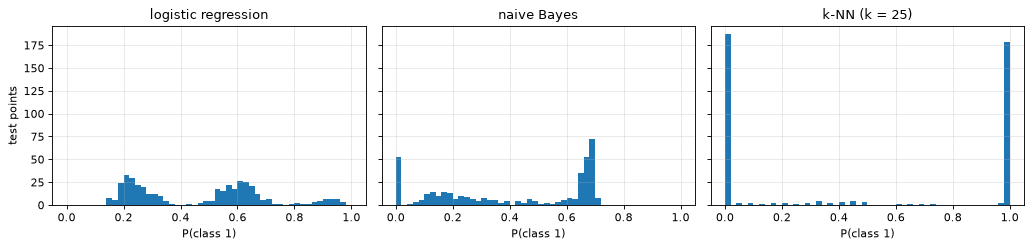

In [10]:
probas = {"logistic regression": predict_proba_logistic(my_lr, Xg_te)[:, 1],
          "naive Bayes": predict_proba_nb(my_nb, Xg_te)[:, 1],
          f"k-NN (k = {K})": my_knn_p[:, 1]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (name, p) in zip(axes, probas.items()):
    ax.hist(p, bins=np.linspace(0, 1, 51))
    ax.set_title(name); ax.set_xlabel("P(class 1)")
    print(f"{name:20s}: distinct values {len(np.unique(np.round(p, 12))):4d}, share below 0.01 or above 0.99: "
          f"{np.mean((p < 0.01) | (p > 0.99)):.0%}")
axes[0].set_ylabel("test points")
plt.tight_layout(); plt.show()

> **Implementation hurdle — the members' probabilities are not on the same scale.** On these 399 test points k-NN
> uses only 19 different values (multiples of 1/25) and is at exactly 0 or 1 for 91 % of them (all 25 neighbours
> agree); naive Bayes is beyond 0.01 / 0.99 for 11 %; logistic regression never is — it hedges everywhere, even where
> it is right. In a soft vote a member that often says 0.00 or 1.00 carries more weight than one that hedges, whether
> or not it deserves it. Nothing in the code is wrong — the danger is in the assumption, and only a calibration check
> (or the library lab's Lab 11) reveals it.

---
## 4 · The whole ensemble vs scikit-learn, on both datasets

Three checks, each one isolating a different part:

* **(i) the voting logic alone:** take scikit-learn's *own fitted members* (`VotingClassifier.estimators_`), feed
  their outputs to `hard_vote` / `soft_vote`, and compare with `VotingClassifier.predict` → must be 100 % identical.
* **(ii) the members alone:** my LR / NB / k-NN vs scikit-learn's.
* **(iii) everything mine vs everything scikit-learn's:** accuracy, % identical predictions, fit time.

In [11]:
def fit_members(X, y, k=25):
    return {"lr": fit_logistic(X, y), "nb": fit_gaussian_nb(X, y), "knn": {"X": X, "y": y, "k": k}}


def member_probas(members, X, classes):
    return np.stack([predict_proba_logistic(members["lr"], X),
                     predict_proba_nb(members["nb"], X),
                     knn_predict_proba(members["knn"]["X"], members["knn"]["y"], X, members["knn"]["k"], classes)])


def sk_members(k=25):
    return [("lr", make_pipeline(StandardScaler(), LogisticRegression())), ("nb", GaussianNB()), ("knn", KNeighborsClassifier(n_neighbors=k))]


rows = []
for name, (X_tr, X_te, y_tr, y_te) in datasets.items():
    classes = np.unique(y_tr)
    t0 = time.perf_counter()
    sk_hard = VotingClassifier(sk_members(), voting="hard").fit(X_tr, y_tr)
    sk_soft = VotingClassifier(sk_members(), voting="soft").fit(X_tr, y_tr)
    t_sk = time.perf_counter() - t0

    # (i) my rules on scikit-learn's fitted members
    sk_labels = np.array([est.predict(X_te) for est in sk_hard.estimators_])
    sk_probas = np.array([est.predict_proba(X_te) for est in sk_soft.estimators_])
    same_hard_i = np.mean(hard_vote(sk_labels, classes) == sk_hard.predict(X_te))
    same_soft_i = np.mean(classes[soft_vote(sk_probas).argmax(axis=1)] == sk_soft.predict(X_te))

    # (ii) member by member
    t0 = time.perf_counter()
    mine = fit_members(X_tr, y_tr)
    my_P = member_probas(mine, X_te, classes)
    my_hard = hard_vote(classes[my_P.argmax(axis=2)], classes)
    my_soft = classes[soft_vote(my_P).argmax(axis=1)]
    t_mine = time.perf_counter() - t0
    member_diff = [np.abs(my_P[b] - sk_probas[b]).max() for b in range(3)]
    member_same = [np.mean(my_P[b].argmax(axis=1) == sk_probas[b].argmax(axis=1)) for b in range(3)]

    rows.append((name, same_hard_i, same_soft_i, member_diff, member_same,
                 (my_hard == y_te).mean(), sk_hard.score(X_te, y_te), np.mean(my_hard == sk_hard.predict(X_te)),
                 (my_soft == y_te).mean(), sk_soft.score(X_te, y_te), np.mean(my_soft == sk_soft.predict(X_te)), t_mine, t_sk))

for r in rows:
    print(f"=== {r[0]} ===")
    print(f"(i)   my vote rules on sklearn's members = VotingClassifier: hard {r[1]:.1%}, soft {r[2]:.1%}")
    print(f"(ii)  max |P difference| lr {r[3][0]:.1e}, nb {r[3][1]:.1e}, knn {r[3][2]:.1e};"
          f" identical member predictions {r[4][0]:.1%}, {r[4][1]:.1%}, {r[4][2]:.1%}")
    print(f"(iii) hard vote accuracy mine {r[5]:.3f} vs sklearn {r[6]:.3f}, identical predictions {r[7]:.1%}")
    print(f"      soft vote accuracy mine {r[8]:.3f} vs sklearn {r[9]:.3f}, identical predictions {r[10]:.1%}")
    print(f"      fit + predict time: mine {r[11] * 1000:.0f} ms, sklearn {r[12] * 1000:.0f} ms (sklearn time = fitting both votes)")

=== good_fit ===
(i)   my vote rules on sklearn's members = VotingClassifier: hard 100.0%, soft 100.0%
(ii)  max |P difference| lr 9.0e-05, nb 7.8e-16, knn 0.0e+00; identical member predictions 100.0%, 100.0%, 100.0%
(iii) hard vote accuracy mine 0.995 vs sklearn 0.995, identical predictions 100.0%
      soft vote accuracy mine 0.987 vs sklearn 0.987, identical predictions 100.0%
      fit + predict time: mine 6 ms, sklearn 4 ms (sklearn time = fitting both votes)
=== bad_fit ===
(i)   my vote rules on sklearn's members = VotingClassifier: hard 100.0%, soft 100.0%
(ii)  max |P difference| lr 1.2e-04, nb 6.7e-16, knn 0.0e+00; identical member predictions 100.0%, 100.0%, 100.0%
(iii) hard vote accuracy mine 0.803 vs sklearn 0.803, identical predictions 100.0%
      soft vote accuracy mine 0.927 vs sklearn 0.927, identical predictions 100.0%
      fit + predict time: mine 3 ms, sklearn 4 ms (sklearn time = fitting both votes)


> **How to read this**
> * **(i)** On both datasets my `hard_vote` / `soft_vote`, fed scikit-learn's own fitted members, reproduce
>   `VotingClassifier.predict` on 100 % of test points: the voting logic (including the tie rule) is the same.
> * **(ii)** Naive Bayes and k-NN match to ~1e-16 and exactly; logistic regression to ~1e-4 (solver tolerance, §2.1).
> * **(iii)** Everything-mine vs everything-scikit-learn: the same accuracies (hard 0.995 / soft 0.987 on the good
>   fit, 0.803 / 0.927 on the bad fit) and 100 % identical predictions.

---
## 5 · Stacking needs out-of-fold predictions

**README §8.1.** Stacking replaces "count the votes" by a small model (here: my logistic regression) that *learns* how
much to trust each member from the members' probabilities. The trap: if the members' probabilities on the training
set come from members that were **trained on those same points**, an over-fitting member looks perfect. A 1-nearest-
neighbour classifier is the extreme case — on its own training points it is always 100 % right (each point is its
own nearest neighbour).

The fix is **out-of-fold** (OOF) predictions: split the training set into 5 folds; for each fold, fit the members on
the other 4 folds and predict the held-out fold. Every training point then gets a prediction from members that never
saw it.

In [12]:
def kfold_indices(n, n_folds, seed=0):
    order = np.random.default_rng(seed).permutation(n)
    return np.array_split(order, n_folds)


def stack_members_fit(X, y):
    return {"lr": fit_logistic(X, y), "nb": fit_gaussian_nb(X, y), "1nn": {"X": X, "y": y}}


def stack_members_p1(members, X):
    """(n, 3) array: each member's P(class 1) - the inputs of the stacker."""
    return np.column_stack([predict_proba_logistic(members["lr"], X)[:, 1],
                            predict_proba_nb(members["nb"], X)[:, 1],
                            knn_predict_proba(members["1nn"]["X"], members["1nn"]["y"], X, 1, classes01)[:, 1]])


def out_of_fold_probas(X, y, n_folds=5, seed=0):
    out = np.zeros((len(y), 3))
    for held_out in kfold_indices(len(y), n_folds, seed):
        keep = np.setdiff1d(np.arange(len(y)), held_out)
        out[held_out] = stack_members_p1(stack_members_fit(X[keep], y[keep]), X[held_out])
    return out


Xs_all, ys_all = make_moons(1200, noise=0.4, random_state=0)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs_all, ys_all, test_size=0.3, random_state=0, stratify=ys_all)
members_all = stack_members_fit(Xs_tr, ys_tr)                         # members refitted on all training data
test_inputs = stack_members_p1(members_all, Xs_te)
for b, name in enumerate(["logistic regression", "naive Bayes", "1-NN"]):
    print(f"{name:20s} training accuracy {np.mean((stack_members_p1(members_all, Xs_tr)[:, b] > 0.5) == ys_tr):.3f}"
          f"   test accuracy {np.mean((test_inputs[:, b] > 0.5) == ys_te):.3f}")

in_sample = stack_members_p1(members_all, Xs_tr)                     # the trap
oof = out_of_fold_probas(Xs_tr, ys_tr)                               # the fix
for label, train_inputs in [("stacker trained on IN-SAMPLE member outputs", in_sample),
                            ("stacker trained on OUT-OF-FOLD member outputs", oof)]:
    stacker = fit_logistic(train_inputs, ys_tr)
    w_raw = stacker["w"] / stacker["scale"]                            # weights per unit of each member's probability
    acc = np.mean((predict_proba_logistic(stacker, test_inputs)[:, 1] > 0.5) == ys_te)
    print(f"\n{label}:\n  weight on (LR, NB, 1-NN) probabilities = {w_raw.round(2)}   test accuracy {acc:.3f}")
print(f"\nfor comparison, plain hard vote of the three: "
      f"{np.mean(hard_vote((test_inputs > 0.5).astype(int).T, classes01) == ys_te):.3f}")

logistic regression  training accuracy 0.850   test accuracy 0.831
naive Bayes          training accuracy 0.848   test accuracy 0.831
1-NN                 training accuracy 1.000   test accuracy 0.803



stacker trained on IN-SAMPLE member outputs:
  weight on (LR, NB, 1-NN) probabilities = [1.39 1.29 9.44]   test accuracy 0.803



stacker trained on OUT-OF-FOLD member outputs:
  weight on (LR, NB, 1-NN) probabilities = [2.63 1.98 1.26]   test accuracy 0.861

for comparison, plain hard vote of the three: 0.831


> **How to read this**
> * 1-NN is perfect on its own training points (1.000) but the *worst* member on new data (0.803).
> * Fed **in-sample** outputs, the stacker sees one member that is never wrong and puts almost all its weight on it
>   (9.44 vs ~1.3): its test accuracy is exactly 1-NN's, 0.803 — worse than a plain hard vote (0.831).
> * Fed **out-of-fold** outputs, the stacker sees 1-NN's real, noisy behaviour, gives it the smallest weight, and
>   reaches 0.861 — better than every member and than the hard vote. This is why scikit-learn's `StackingClassifier`
>   uses `cv=5` by default.

---
# Summary — what each section showed

| Section | Claim | Verdict |
|---|---|---|
| 1 | The vote rules reproduce README §5 exactly; ties go to the first class like scikit-learn (the `max(…, key=count)` one-liner does not) | ✔ |
| 1 | Probability columns must be aligned by class name before averaging | ✔ hurdle shown |
| 2.1 | Gradient descent on C·Σ log-loss + ½‖w‖² gives scikit-learn's logistic regression | ✔ (differences = sklearn's stopping tolerance) |
| 2.1 | Naive sigmoid / log-loss overflow; the stable versions do not | ✔ hurdle shown |
| 2.2 | Gaussian NB with ε = 10⁻⁹ × max variance and log-sum-exp = scikit-learn | ✔ to ~10⁻¹⁶ |
| 2.3 | k-NN probabilities = share of the k neighbours | ✔ exact |
| 3 | Members' probabilities live on different scales | ✔ hurdle shown |
| 4 | (i) my vote rules on sklearn's members = `VotingClassifier`; (ii) members; (iii) whole ensemble | ✔ |
| 5 | A stacker fed in-sample outputs over-trusts 1-NN; out-of-fold outputs fix it | ✔ hurdle shown |